# Prérequis

In [103]:
import numpy as np
import matplotlib.pyplot as plt

N = 5000

# Part I – Simulating Uniform Convergence

## Empirical Risk as a Random Variable

p=0.1, m= 10 : moyenne empirique=0.0988, risque réel=0.10, écart-type=0.0944
p=0.1, m= 50 : moyenne empirique=0.1003, risque réel=0.10, écart-type=0.0421
p=0.1, m=100 : moyenne empirique=0.1011, risque réel=0.10, écart-type=0.0302
p=0.1, m=500 : moyenne empirique=0.1001, risque réel=0.10, écart-type=0.0134


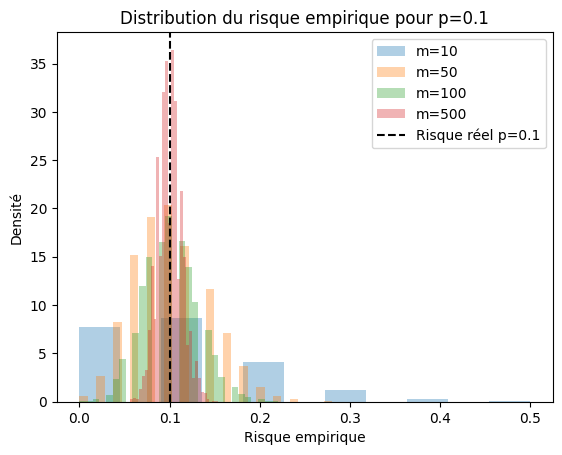

p=0.3, m= 10 : moyenne empirique=0.3004, risque réel=0.30, écart-type=0.1460
p=0.3, m= 50 : moyenne empirique=0.2994, risque réel=0.30, écart-type=0.0658
p=0.3, m=100 : moyenne empirique=0.3002, risque réel=0.30, écart-type=0.0455
p=0.3, m=500 : moyenne empirique=0.3002, risque réel=0.30, écart-type=0.0204


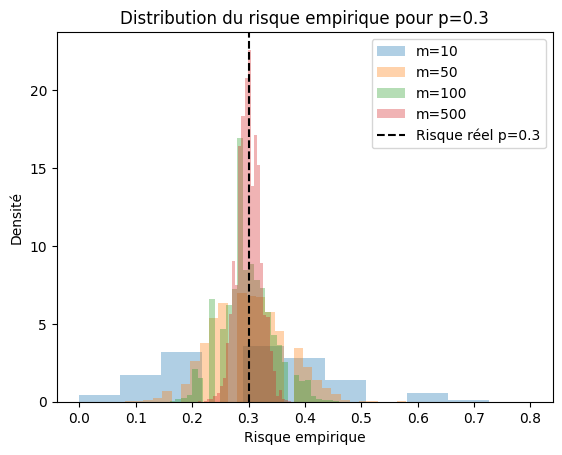

p=0.5, m= 10 : moyenne empirique=0.5028, risque réel=0.50, écart-type=0.1594
p=0.5, m= 50 : moyenne empirique=0.5007, risque réel=0.50, écart-type=0.0714
p=0.5, m=100 : moyenne empirique=0.5012, risque réel=0.50, écart-type=0.0500
p=0.5, m=500 : moyenne empirique=0.4994, risque réel=0.50, écart-type=0.0222


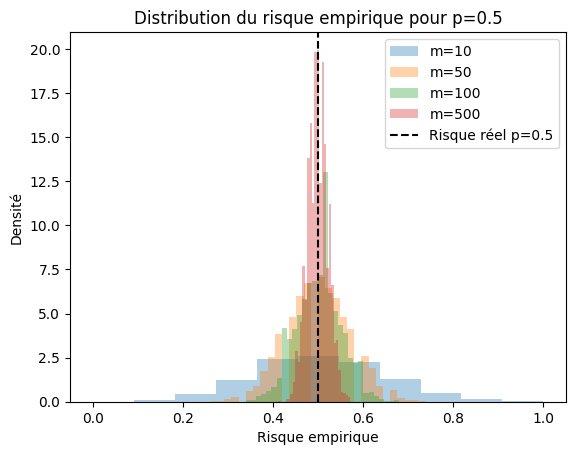

In [104]:
risques_reels = [0.1, 0.3, 0.5]
tailles_m_q1 = [10, 50, 100, 500]
nb_simulations_q1 = N

for p in risques_reels:
    fig, ax = plt.subplots()
    for m in tailles_m_q1:
        erreurs = np.random.binomial(m, p, size=nb_simulations_q1)
        risques_empiriques = erreurs / m
        moyenne = np.mean(risques_empiriques)
        ecart_type = np.std(risques_empiriques)
        print(
            f"p={p:.1f}, m={m:3d} : moyenne empirique={moyenne:.4f}, "
            f"risque réel={p:.2f}, écart-type={ecart_type:.4f}"
        )
        ax.hist(
            risques_empiriques, bins=min(30, m + 1), density=True,
            alpha=0.35, label=f"m={m}"
        )
    ax.axvline(p, linestyle="--", color="black", label=f"Risque réel p={p}")
    ax.set_xlabel("Risque empirique")
    ax.set_ylabel("Densité")
    ax.set_title(f"Distribution du risque empirique pour p={p}")
    ax.legend()
    plt.show()

### Analyse

Le risque empirique est la proportion d'erreurs observées dans l'échantillon. Comme l'échantillon change aléatoirement, le risque empirique varie d'une simulation à l'autre.

Pour chaque risque réel \(p\), la moyenne des risques empiriques simulés est proche de \(p\). C'est cohérent avec le fait que le risque empirique est un estimateur non biaisé du risque réel.

Lorsque la taille \(m\) augmente, les distributions deviennent plus concentrées autour de \(p\) : les estimations sont moins variables et donc plus stables. Les petites tailles d'échantillon peuvent produire des valeurs assez éloignées du risque réel, tandis que les grandes tailles d'échantillon donnent généralement une estimation plus précise.

## Deviation Between Empirical and True Risk

m=  10 : probabilité simulée=0.0638, borne affichée=1.0000
m=  20 : probabilité simulée=0.0388, borne affichée=1.0000
m=  50 : probabilité simulée=0.0086, borne affichée=0.7358
m= 100 : probabilité simulée=0.0004, borne affichée=0.2707
m= 200 : probabilité simulée=0.0000, borne affichée=0.0366
m= 500 : probabilité simulée=0.0000, borne affichée=0.0001
m=1000 : probabilité simulée=0.0000, borne affichée=0.0000


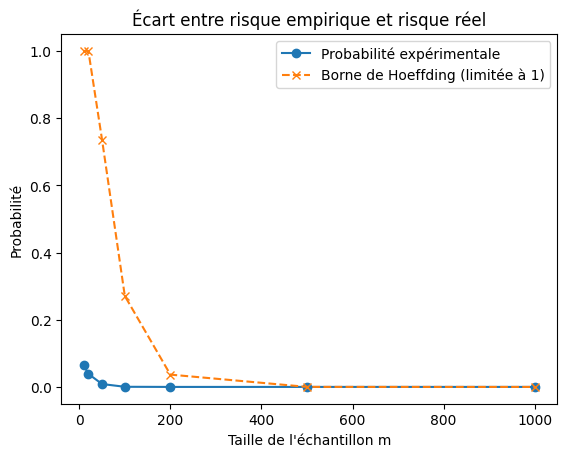

In [105]:
epsilon = 0.1
p = 0.1
tailles_m_q2 = [10, 20, 50, 100, 200, 500, 1000]
probas_experimentales_q2 = []
bornes_hoeffding_q2 = []

for m in tailles_m_q2:
    erreurs = np.random.binomial(m, p, size=N)
    risques_empiriques = erreurs / m
    ecarts = np.abs(risques_empiriques - p)
    proba = np.mean(ecarts > epsilon)
    borne_brute = 2 * np.exp(-2 * m * epsilon**2)
    borne_affichee = min(1.0, borne_brute)
    probas_experimentales_q2.append(proba)
    bornes_hoeffding_q2.append(borne_affichee)
    print(f"m={m:4d} : probabilité simulée={proba:.4f}, borne affichée={borne_affichee:.4f}")

plt.plot(tailles_m_q2, probas_experimentales_q2, marker="o",
         label="Probabilité expérimentale")
plt.plot(tailles_m_q2, bornes_hoeffding_q2, marker="x", linestyle="--",
         label="Borne de Hoeffding (limitée à 1)")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Probabilité")
plt.title("Écart entre risque empirique et risque réel")
plt.legend()
plt.show()

### Analyse

La probabilité expérimentale estime la fréquence des simulations dans lesquelles le risque empirique s'éloigne du risque réel de plus de 0,1. Elle tend généralement à diminuer lorsque la taille de l'échantillon augmente.

La borne de Hoeffding est une garantie supérieure, pas une prédiction exacte : elle n'a pas besoin d'être égale à la probabilité observée. Elle est souvent conservatrice et peut être peu informative pour les petites tailles d'échantillon. Comme une probabilité ne peut pas dépasser 1, on affiche ici le minimum entre 1 et la borne brute. Cette limitation ne change pas le sens de la garantie.

## From One Hypothesis to Uniform Convergence

m=  10 : P(Delta_S > epsilon) simulée=0.9648, borne=1.0000
m=  20 : P(Delta_S > epsilon) simulée=0.8584, borne=1.0000
m=  50 : P(Delta_S > epsilon) simulée=0.4682, borne=1.0000
m= 100 : P(Delta_S > epsilon) simulée=0.1318, borne=1.0000
m= 200 : P(Delta_S > epsilon) simulée=0.0114, borne=0.1832
m= 500 : P(Delta_S > epsilon) simulée=0.0000, borne=0.0005
m=1000 : P(Delta_S > epsilon) simulée=0.0000, borne=0.0000


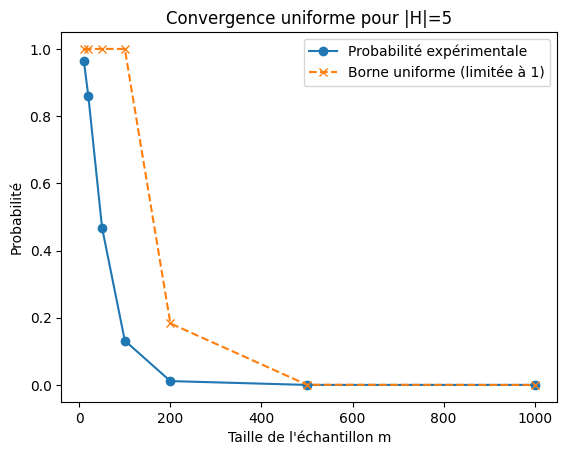

In [106]:
epsilon_q3 = 0.1
K_q3 = 5
tailles_m_q3 = [10, 20, 50, 100, 200, 500, 1000]
risques_reels_q3 = np.random.rand(K_q3)
probas_experimentales_q3 = []
bornes_uniformes_q3 = []

for m in tailles_m_q3:
    erreurs = np.random.binomial(
        m, risques_reels_q3[:, None], size=(K_q3, N)
    )
    risques_empiriques = erreurs / m
    ecarts = np.abs(risques_empiriques - risques_reels_q3[:, None])
    delta_s = np.max(ecarts, axis=0)
    proba = np.mean(delta_s > epsilon_q3)
    borne = min(1.0, 2 * K_q3 * np.exp(-2 * m * epsilon_q3**2))
    probas_experimentales_q3.append(proba)
    bornes_uniformes_q3.append(borne)
    print(f"m={m:4d} : P(Delta_S > epsilon) simulée={proba:.4f}, borne={borne:.4f}")

plt.plot(tailles_m_q3, probas_experimentales_q3, marker="o",
         label="Probabilité expérimentale")
plt.plot(tailles_m_q3, bornes_uniformes_q3, marker="x", linestyle="--",
         label="Borne uniforme (limitée à 1)")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Probabilité")
plt.title(f"Convergence uniforme pour |H|={K_q3}")
plt.legend()
plt.show()

### Analyse

La convergence uniforme ne porte pas sur une seule hypothèse : elle exige que les risques empiriques de toutes les hypothèses soient proches de leurs risques réels en même temps. Pour cela, on mesure le plus grand écart parmi les hypothèses.

La probabilité qu'au moins une hypothèse dépasse le seuil d'erreur tend généralement à diminuer avec la taille de l'échantillon. La borne uniforme contient le facteur \(|H|\), car il faut contrôler plusieurs hypothèses simultanément. Elle peut être large, mais donne une garantie valable pour toute la classe finie.

## Effect of the Size of the Hypothesis Class

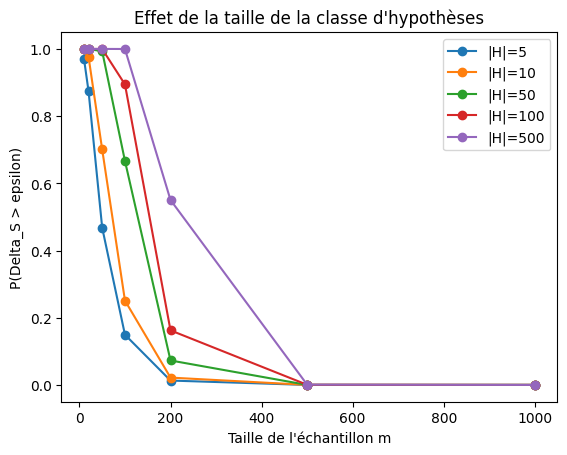

In [107]:
N = 5000
epsilon_q4 = 0.1
tailles_H_q4 = [5, 10, 50, 100, 500]
tailles_m_q4 = [10, 20, 50, 100, 200, 500, 1000]
probas_par_H_q4 = {}

for K in tailles_H_q4:
    risques_reels = np.random.rand(K)
    probas = []
    for m in tailles_m_q4:
        erreurs = np.random.binomial(
            m, risques_reels[:, None], size=(K, N)
        )
        risques_empiriques = erreurs / m
        delta_s = np.max(np.abs(risques_empiriques - risques_reels[:, None]), axis=0)
        probas.append(np.mean(delta_s > epsilon_q4))
    probas_par_H_q4[K] = probas
    plt.plot(tailles_m_q4, probas, marker="o", label=f"|H|={K}")

plt.xlabel("Taille de l'échantillon m")
plt.ylabel("P(Delta_S > epsilon)")
plt.title("Effet de la taille de la classe d'hypothèses")
plt.legend()
plt.show()

### Analyse

Une classe plus grande contient davantage d'hypothèses à contrôler simultanément. Il devient alors plus probable qu'au moins une hypothèse ait un écart important entre son risque empirique et son risque réel. À taille d'échantillon identique, une classe plus grande demande donc généralement davantage de données pour atteindre la même garantie de convergence uniforme.

La borne théorique fait apparaître \(\log |H|\) dans la taille d'échantillon suffisante. La dépendance est logarithmique : la quantité de données requise augmente avec la taille de la classe, mais pas proportionnellement à \(|H|\). Les courbes peuvent ne pas être parfaitement ordonnées à chaque point à cause du hasard des simulations.

## Experimental Sample Complexity

m=  10 : P(Delta_S > epsilon) estimée=1.0000
m=  20 : P(Delta_S > epsilon) estimée=1.0000
m=  50 : P(Delta_S > epsilon) estimée=0.9950
m= 100 : P(Delta_S > epsilon) estimée=0.7234
m= 200 : P(Delta_S > epsilon) estimée=0.1056
m= 300 : P(Delta_S > epsilon) estimée=0.0120
m= 350 : P(Delta_S > epsilon) estimée=0.0028
m= 500 : P(Delta_S > epsilon) estimée=0.0004
m= 750 : P(Delta_S > epsilon) estimée=0.0000
m=1000 : P(Delta_S > epsilon) estimée=0.0000
m=1500 : P(Delta_S > epsilon) estimée=0.0000
m=2000 : P(Delta_S > epsilon) estimée=0.0000

Plus petite taille testée respectant le seuil : 300
Taille théorique suffisante : 346


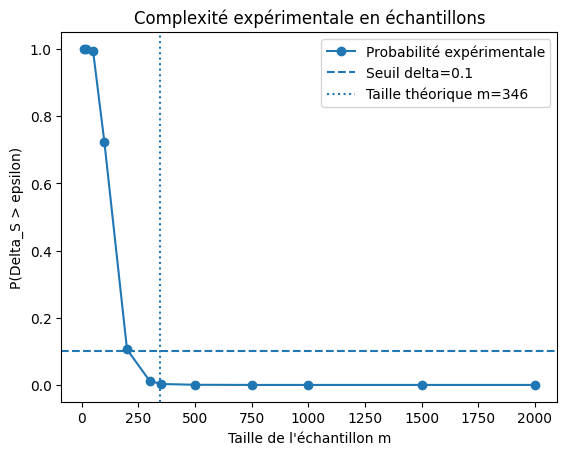

In [108]:
epsilon_q5 = 0.1
delta_q5 = 0.1
K_q5 = 50
tailles_m_q5 = [10, 20, 50, 100, 200, 300, 350, 500, 750, 1000, 1500, 2000]
risques_reels_q5 = np.random.rand(K_q5)
probas_q5 = []

for m in tailles_m_q5:
    erreurs = np.random.binomial(
        m, risques_reels_q5[:, None], size=(K_q5, N)
    )
    risques_empiriques = erreurs / m
    delta_s = np.max(np.abs(risques_empiriques - risques_reels_q5[:, None]), axis=0)
    proba = np.mean(delta_s > epsilon_q5)
    probas_q5.append(proba)
    print(f"m={m:4d} : P(Delta_S > epsilon) estimée={proba:.4f}")

m_experimental_q5 = next(
    (m for m, proba in zip(tailles_m_q5, probas_q5) if proba <= delta_q5),
    None
)
m_theorique_q5 = int(np.ceil(
    np.log(2 * K_q5 / delta_q5) / (2 * epsilon_q5**2)
))

print("\nPlus petite taille testée respectant le seuil :", m_experimental_q5)
print("Taille théorique suffisante :", m_theorique_q5)

plt.plot(tailles_m_q5, probas_q5, marker="o", label="Probabilité expérimentale")
plt.axhline(delta_q5, linestyle="--", label=f"Seuil delta={delta_q5}")
plt.axvline(m_theorique_q5, linestyle=":", label=f"Taille théorique m={m_theorique_q5}")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("P(Delta_S > epsilon)")
plt.title("Complexité expérimentale en échantillons")
plt.legend()
plt.show()

### Analyse

La taille expérimentale est la première taille testée pour laquelle la probabilité simulée est inférieure ou égale à 0,1. Elle dépend de la grille de tailles choisie et du hasard des simulations : ce n'est donc pas nécessairement le minimum exact.

Avec les paramètres retenus, la borne donne une taille théorique suffisante de 346.
Cette valeur est une garantie suffisante, pas forcément la plus petite taille nécessaire en pratique. La borne est construite pour assurer une garantie générale et peut être conservatrice.

# Part II - Simulating No-Free-Lunch

## Seen and Unseen Inputs

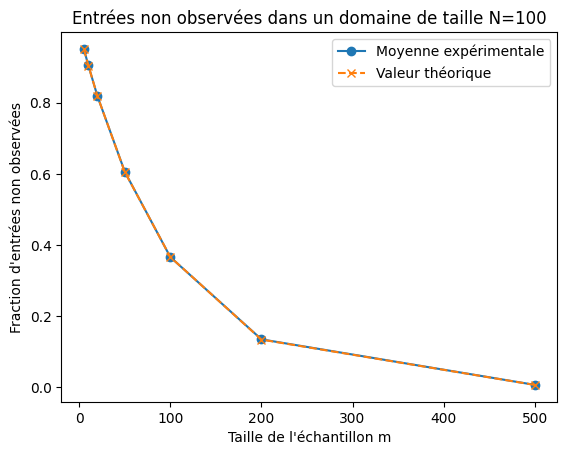

In [109]:
N_q6 = 100
tailles_m_q6 = [5, 10, 20, 50, 100, 200, 500]
proportions_experimentales_q6 = []
proportions_theoriques_q6 = []

for m in tailles_m_q6:
    fractions_inconnues = []
    for _ in range(N):
        tirages = np.random.randint(1, N_q6 + 1, size=m)
        nb_observees = len(np.unique(tirages))
        fractions_inconnues.append(1 - nb_observees / N_q6)
    proportions_experimentales_q6.append(np.mean(fractions_inconnues))
    proportions_theoriques_q6.append((1 - 1/N_q6)**m)

plt.plot(tailles_m_q6, proportions_experimentales_q6, marker="o",
         label="Moyenne expérimentale")
plt.plot(tailles_m_q6, proportions_theoriques_q6, marker="x", linestyle="--",
         label="Valeur théorique")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Fraction d'entrées non observées")
plt.title(f"Entrées non observées dans un domaine de taille N={N_q6}")
plt.legend()
plt.show()

### Analyse

Les tirages sont effectués avec remise : une entrée peut donc apparaître plusieurs fois. Lorsque \(m\) augmente, davantage d'entrées distinctes sont généralement observées et la fraction d'entrées inconnues diminue.

Pour une entrée fixée, la probabilité de ne pas la tirer à chaque tirage est \(1-1/N\). L'indépendance des tirages donne donc \((1-1/N)^m\) pour la probabilité qu'elle reste inconnue après \(m\) tirages.

La fraction d'entrées inconnues est la moyenne des indicatrices de non-observation sur les \(N\) entrées. Par linéarité de l'espérance, son espérance est égale à la probabilité de non-observation d'une entrée fixée, soit \((1-1/N)^m\). La moyenne simulée doit donc se rapprocher de la courbe théorique.

## Error on Unseen Inputs

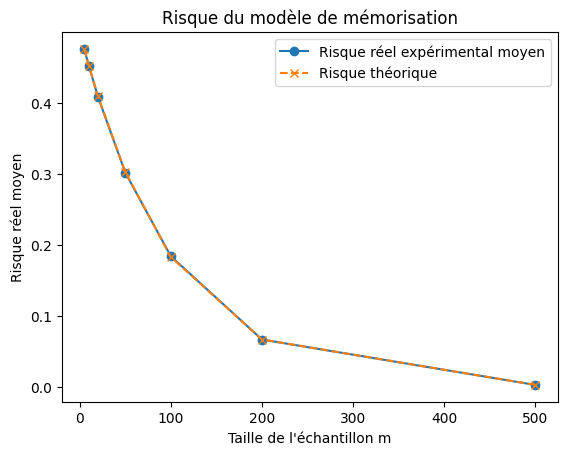

In [110]:
N_q7 = 100
tailles_m_q7 = [5, 10, 20, 50, 100, 200, 500]
risques_experimentaux_q7 = []
risques_theoriques_q7 = []

X_complet_q7 = np.arange(1, N_q7 + 1)

for m in tailles_m_q7:
    risques = []
    for _ in range(N):
        # Une nouvelle cible aléatoire : une étiquette par entrée du domaine
        cible = np.random.randint(0, 2, size=N_q7)
        X_train = np.random.randint(1, N_q7 + 1, size=m)
        Y_train = cible[X_train - 1]

        # Prédiction 0 par défaut, puis mémorisation des étiquettes observées
        predictions = np.zeros(N_q7, dtype=int)
        predictions[X_train - 1] = Y_train

        risques.append(np.mean(predictions != cible))

    risques_experimentaux_q7.append(np.mean(risques))
    risques_theoriques_q7.append(0.5 * (1 - 1/N_q7)**m)

plt.plot(tailles_m_q7, risques_experimentaux_q7, marker="o",
         label="Risque réel expérimental moyen")
plt.plot(tailles_m_q7, risques_theoriques_q7, marker="x", linestyle="--",
         label="Risque théorique")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Risque réel moyen")
plt.title("Risque du modèle de mémorisation")
plt.legend()
plt.show()

### Analyse

Le modèle mémorise correctement les étiquettes des entrées observées, donc il ne commet pas d'erreur sur ces entrées. Sur une entrée non observée, il prédit 0, mais l'étiquette réelle est aléatoire et vaut 1 avec probabilité \(1/2\). Sa probabilité d'erreur sur une entrée inconnue est donc \(1/2\).

Le risque réel moyen correspond à la moitié de la proportion attendue d'entrées non observées. Il vaut théoriquement :

$$
\mathbb{E}[L_D(A(S))] = \frac{1}{2}\left(1-\frac{1}{N}\right)^m
$$

Les résultats expérimentaux doivent se rapprocher de cette formule, avec de petites différences dues au nombre fini de simulations.

## Changing the Predictions on Unseen Inputs

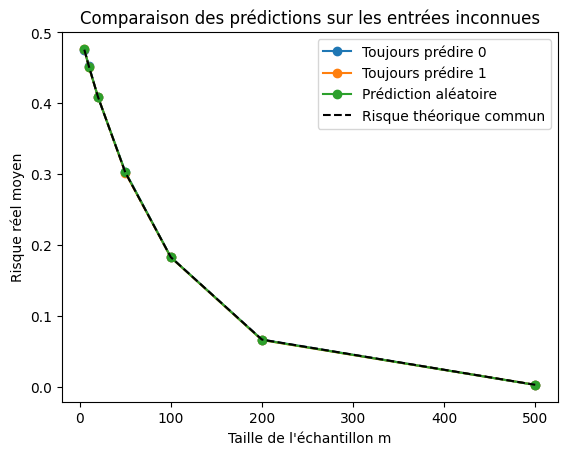

In [111]:
N_q8 = 100
tailles_m_q8 = [5, 10, 20, 50, 100, 200, 500]
strategies_q8 = ["Toujours prédire 0", "Toujours prédire 1", "Prédiction aléatoire"]
risques_moyens_q8 = {nom: [] for nom in strategies_q8}
risques_theoriques_q8 = []

for m in tailles_m_q8:
    risques_par_strategie = {nom: [] for nom in strategies_q8}
    for _ in range(N):
        cible = np.random.randint(0, 2, size=N_q8)
        X_train = np.random.randint(1, N_q8 + 1, size=m)
        Y_train = cible[X_train - 1]
        observees = np.zeros(N_q8, dtype=bool)
        observees[X_train - 1] = True

        predictions0 = np.zeros(N_q8, dtype=int)
        predictions1 = np.ones(N_q8, dtype=int)
        predictions_random = np.random.randint(0, 2, size=N_q8)

        # Pour les entrées observées, toutes les stratégies mémorisent le label.
        for predictions in (predictions0, predictions1, predictions_random):
            predictions[X_train - 1] = Y_train

        risques_par_strategie["Toujours prédire 0"].append(np.mean(predictions0 != cible))
        risques_par_strategie["Toujours prédire 1"].append(np.mean(predictions1 != cible))
        risques_par_strategie["Prédiction aléatoire"].append(np.mean(predictions_random != cible))

    for nom in strategies_q8:
        risques_moyens_q8[nom].append(np.mean(risques_par_strategie[nom]))
    risques_theoriques_q8.append(0.5 * (1 - 1/N_q8)**m)

for nom in strategies_q8:
    plt.plot(tailles_m_q8, risques_moyens_q8[nom], marker="o", label=nom)
plt.plot(tailles_m_q8, risques_theoriques_q8, linestyle="--", color="black",
         label="Risque théorique commun")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Risque réel moyen")
plt.title("Comparaison des prédictions sur les entrées inconnues")
plt.legend()
plt.show()

### Analyse

Pour une cible complètement aléatoire, la véritable étiquette d'une entrée inconnue vaut 0 ou 1 avec la même probabilité. Prédire toujours 0 entraîne donc une probabilité d'erreur de \(1/2\), et prédire toujours 1 donne la même probabilité.

Une prédiction aléatoire indépendante de la cible a elle aussi une probabilité d'erreur de \(1/2\). Les trois stratégies ont donc le même risque théorique attendu, égal à la moitié de la fraction attendue d'entrées non observées. Les courbes peuvent différer légèrement dans les simulations, mais aucune stratégie ne doit systématiquement surpasser les autres.

Cela illustre le principe No-Free-Lunch : sans structure connue dans les fonctions cibles, les données observées ne permettent pas de deviner les étiquettes arbitraires des entrées inconnues.

# Part III - Introducing Prior Knowledge

## Learning with a Machine Inductive Bias

m=   5 : risque réel moyen ERM=0.1400
m=  10 : risque réel moyen ERM=0.0776
m=  20 : risque réel moyen ERM=0.0415
m=  50 : risque réel moyen ERM=0.0143
m= 100 : risque réel moyen ERM=0.0055
m= 200 : risque réel moyen ERM=0.0015
m= 500 : risque réel moyen ERM=0.0001


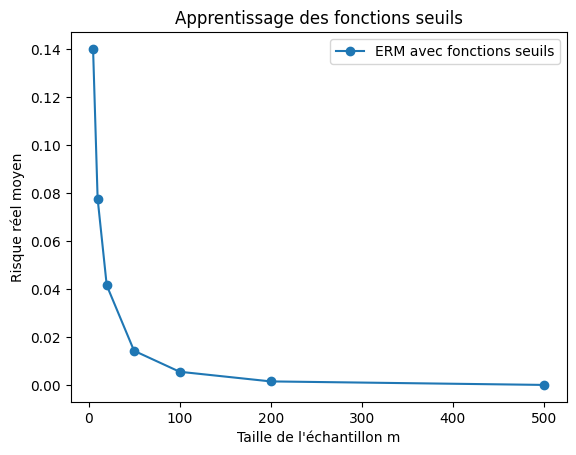

In [112]:
N_q9 = 100
tailles_m_q9 = [5, 10, 20, 50, 100, 200, 500]
risques_erm_moyens_q9 = []
nb_simulations_q9 = N
X_complet_q9 = np.arange(1, N_q9 + 1)

for m in tailles_m_q9:
    risques = []
    for _ in range(nb_simulations_q9):
        theta_vrai = np.random.randint(1, N_q9)  # 1,...,N-1
        X_train = np.random.randint(1, N_q9 + 1, size=m)
        Y_train = (X_train > theta_vrai).astype(int)

        # ERM : choisir le seuil ayant le moins d'erreurs d'entraînement.
        # En cas d'égalité, np.argmin sélectionne le premier seuil minimisant l'erreur.
        erreurs_par_seuil = []
        seuils = np.arange(1, N_q9)
        for t in seuils:
            predictions_train = (X_train > t).astype(int)
            erreurs_par_seuil.append(np.sum(predictions_train != Y_train))

        meilleur_t = seuils[int(np.argmin(erreurs_par_seuil))]
        predictions_completes = (X_complet_q9 > meilleur_t).astype(int)
        cible_complete = (X_complet_q9 > theta_vrai).astype(int)
        risques.append(np.mean(predictions_completes != cible_complete))

    risques_erm_moyens_q9.append(np.mean(risques))
    print(f"m={m:4d} : risque réel moyen ERM={risques_erm_moyens_q9[-1]:.4f}")

plt.plot(tailles_m_q9, risques_erm_moyens_q9, marker="o",
         label="ERM avec fonctions seuils")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Risque réel moyen")
plt.title("Apprentissage des fonctions seuils")
plt.legend()
plt.show()

### Analyse

L'algorithme ERM essaie les seuils possibles et choisit celui qui commet le moins d'erreurs sur l'échantillon d'apprentissage. Le risque réel est ensuite calculé sur l'ensemble des \(N\) entrées, et non seulement sur les données utilisées pour apprendre.

Lorsque la taille de l'échantillon augmente, les exemples donnent généralement une meilleure indication de la position du seuil réel. Le risque moyen diminue donc. Comme la classe d'hypothèses correspond à la structure de la cible, le modèle peut généraliser aux entrées non observées au lieu de simplement mémoriser les exemples.

## Random Targets vs. Structured Targets

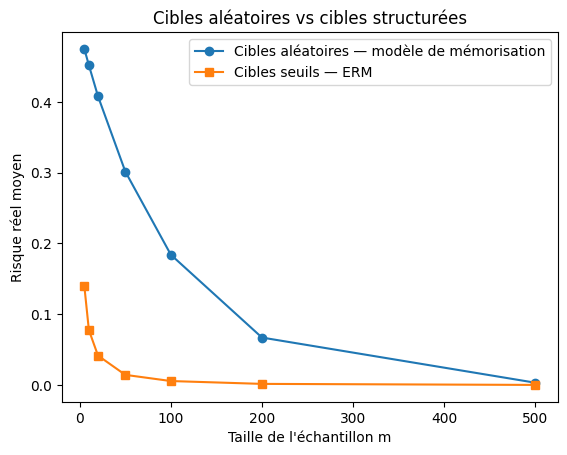

In [113]:
plt.plot(tailles_m_q7, risques_experimentaux_q7, marker="o",
         label="Cibles aléatoires — modèle de mémorisation")
plt.plot(tailles_m_q9, risques_erm_moyens_q9, marker="s",
         label="Cibles seuils — ERM")
plt.xlabel("Taille de l'échantillon m")
plt.ylabel("Risque réel moyen")
plt.title("Cibles aléatoires vs cibles structurées")
plt.legend()
plt.show()

### Analyse

Avec des cibles entièrement aléatoires, aucune règle simple ne permet de déduire les étiquettes inconnues. Le modèle de mémorisation ne peut qu'apprendre les étiquettes déjà observées.

Avec les fonctions seuils, on sait au contraire que la cible suit une règle particulière : les étiquettes changent une seule fois, au niveau du seuil. L'ERM exploite cette structure pour estimer le seuil et faire des prédictions sur des entrées non observées.

Le choix préalable de la classe des fonctions seuils est un **biais inductif**. Il aide à généraliser parce qu'il réduit les fonctions considérées aux règles compatibles avec le problème. Cette comparaison illustre que la généralisation dépend à la fois des données disponibles et des hypothèses que le modèle utilise.

## Analyse finale

Les expériences montrent que la généralisation dépend de la quantité de données et des hypothèses utilisées par l'algorithme.

1. **Concentration du risque empirique.** Le risque empirique varie d'un échantillon à l'autre. Quand \(m\) augmente, il devient plus concentré autour du risque réel. La borne de Hoeffding contrôle théoriquement la probabilité d'un écart important.

2. **Convergence uniforme.** Il faut contrôler simultanément les écarts pour toutes les hypothèses de la classe, et pas seulement pour une hypothèse choisie. Une classe plus grande rend ce contrôle plus difficile. Les bornes de classe finie dépendent de log|H|, ce qui signifie que la taille d'échantillon suffisante augmente logarithmiquement avec le nombre d'hypothèses.

3. **Bornes conservatrices.** Une borne théorique fournit une garantie suffisante, mais elle n'est pas forcément égale à la probabilité observée. Elle peut donc conduire à une taille d'échantillon supérieure à celle qui semble nécessaire dans les simulations.

4. **Principe No-Free-Lunch.** Lorsque les cibles sont totalement aléatoires, les étiquettes des entrées inconnues sont imprévisibles à partir des seules observations. Les stratégies qui prédisent toujours 0, toujours 1 ou une étiquette aléatoire ont la même erreur théorique moyenne sur ces entrées.

5. **Rôle du biais inductif.** Avec des cibles seuils, le modèle suppose que la fonction appartient à la famille des fonctions seuils. Cette hypothèse est adaptée à la cible et permet d'utiliser les observations pour estimer la règle, puis prédire des entrées non observées.

**Conclusion.** Avoir davantage de données améliore généralement l'estimation des risques, mais cela ne suffit pas à apprendre efficacement n'importe quelle fonction. Pour généraliser, l'algorithme doit également exploiter des hypothèses adaptées à la structure du problème. Les fonctions seuils illustrent comment un biais inductif pertinent permet de généraliser au-delà des exemples observés, contrairement au cas de cibles complètement aléatoires.